In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [22]:
df = pd.read_csv('super.csv',encoding='cp1252')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [23]:
df.head()
df['Order Date']=pd.to_datetime(df['Order Date'])

In [26]:
df['Month']=df['Order Date'].dt.month



In [28]:
monthly_sales = df.groupby('Month')['Sales'].sum()

In [34]:
monthly_sales.head(15)

,Sales
Month,
1,94924.8356
2,59751.2514
3,205005.4888
4,137762.1286
5,155028.8117
6,152718.6793
7,147238.0970
8,159044.0630
9,307649.9457


([<matplotlib.axis.XTick at 0x7d46fc5e5a90>,
 [Text(0, 0, 'Jan'),
  Text(1, 0, 'Feb'),
  Text(2, 0, 'Mar'),
  Text(3, 0, 'Apr'),
  Text(4, 0, 'May'),
  Text(5, 0, 'Jun'),
  Text(6, 0, 'July'),
  Text(7, 0, 'August'),
  Text(8, 0, 'Sep'),
  Text(9, 0, 'Oct'),
  Text(10, 0, 'Nov'),
  Text(11, 0, 'Dec')])

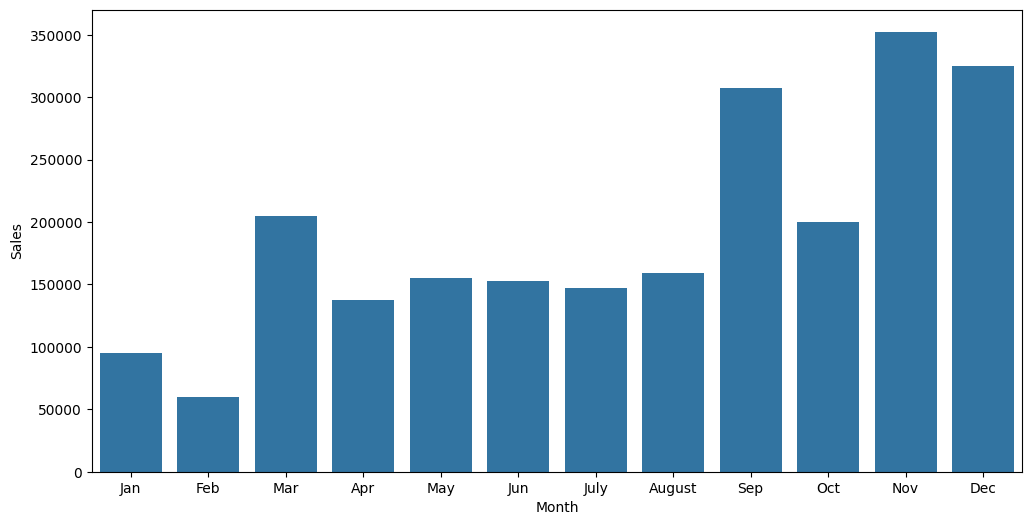

In [91]:
plt.figure(figsize=(12,6))
sns.barplot(data = monthly_sales )
plt.xticks(ticks=range(12),labels=['Jan','Feb','Mar','Apr','May','Jun','July','August','Sep','Oct','Nov','Dec'])


([<matplotlib.axis.XTick at 0x7d46fc2f07d0>,
 [Text(1, 0, 'Jan'),
  Text(2, 0, 'Feb'),
  Text(3, 0, 'Mar'),
  Text(4, 0, 'Apr'),
  Text(5, 0, 'May'),
  Text(6, 0, 'Jun'),
  Text(7, 0, 'July'),
  Text(8, 0, 'August'),
  Text(9, 0, 'Sep'),
  Text(10, 0, 'Oct'),
  Text(11, 0, 'Nov'),
  Text(12, 0, 'Dec')])

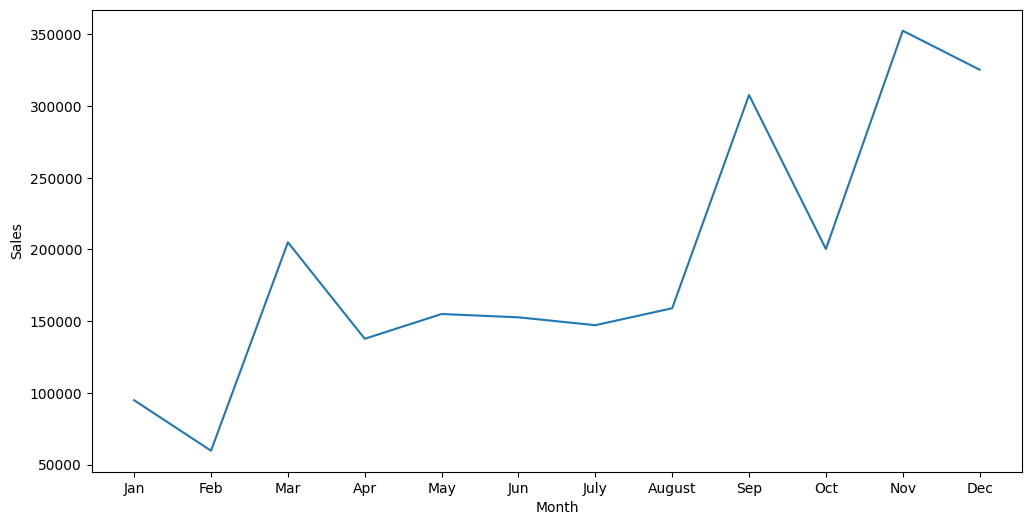

In [96]:
plt.figure(figsize=(12,6))
sns.lineplot(data = monthly_sales )
plt.xticks(ticks=range(1,13),labels=['Jan','Feb','Mar','Apr','May','Jun','July','August','Sep','Oct','Nov','Dec'])


([<matplotlib.patches.Wedge at 0x7d46fc187110>,
 [Text(1.0907441928481723, 0.1423977028185121, 'Jan'),
  Text(1.0365347640114335, 0.3682331910566482, 'Feb'),
  Text(0.838896301406973, 0.7115145785475525, 'Mar'),
  Text(0.4269552795780603, 1.0137599268270672, 'Apr'),
  Text(-0.0019794576625517387, 1.099998218974632, 'May'),
  Text(-0.4512135798851642, 1.0031980389370858, 'Jun'),
  Text(-0.8138592807619245, 0.7400223450124213, 'July'),
  Text(-1.0444863105978646, 0.34503383453461656, 'August'),
  Text(-1.0444400916537349, -0.34517371705611966, 'Sep'),
  Text(-0.5814311422278571, -0.9337761117353611, 'Oct'),
  Text(0.21751606771450926, -1.0782795371729992, 'Nov'),
  Text(0.9929367499137636, -0.47336731052185277, 'Dec')])

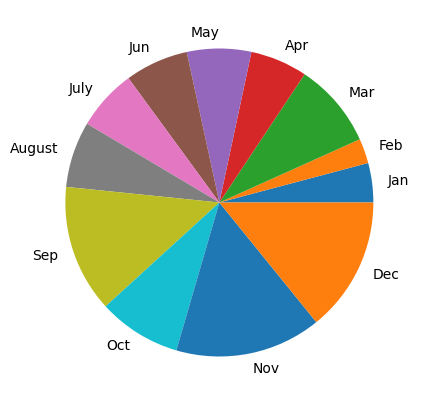

In [100]:
plt.figure(figsize=(5,5),)
plt.pie(monthly_sales,labels=['Jan','Feb','Mar','Apr','May','Jun','July','August','Sep','Oct','Nov','Dec'])

In [97]:
monthly_sales.dtypes

dtype('float64')

In [99]:
monthly_sales.head(10)

,Sales
Month,
1,94924.8356
2,59751.2514
3,205005.4888
4,137762.1286
5,155028.8117
6,152718.6793
7,147238.0970
8,159044.0630
9,307649.9457


<Axes: xlabel='Sub-Category', ylabel='Sales'>

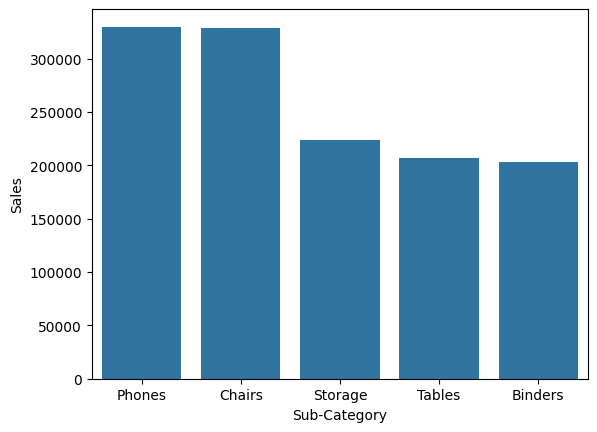

In [117]:
#Task 2
df.head()
sub_category = df.groupby('Sub-Category')['Sales'].sum()
sub_category = sub_category.nlargest(5)
sns.barplot(data=sub_category)

,Sales
Sub-Category,
Accessories,167380.3180
Appliances,107532.1610
Art,27118.7920
Binders,203412.7330
Bookcases,114879.9963


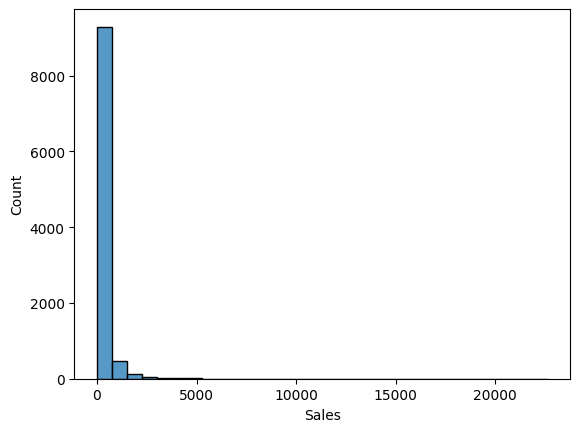

In [143]:
sns.histplot(data=df, x="Sales", bins=30)
plt.show()

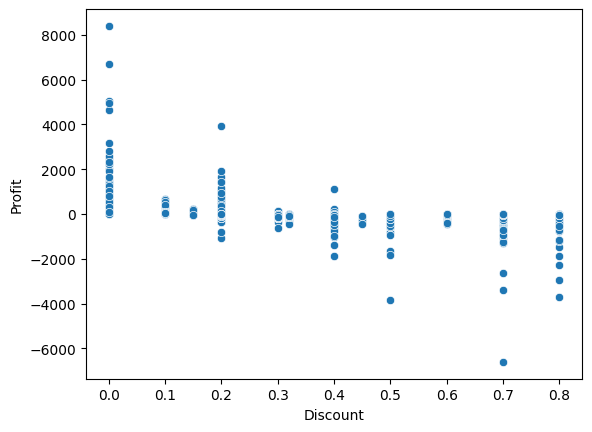

In [119]:
sns.scatterplot(data=df, x="Discount", y="Profit")
plt.show()

In [122]:
region_sales = df.groupby("Region")["Sales"].sum().reset_index()

print(region_sales)

    Region        Sales
0  Central  501239.8908
1     East  678781.2400
2    South  391721.9050
3     West  725457.8245


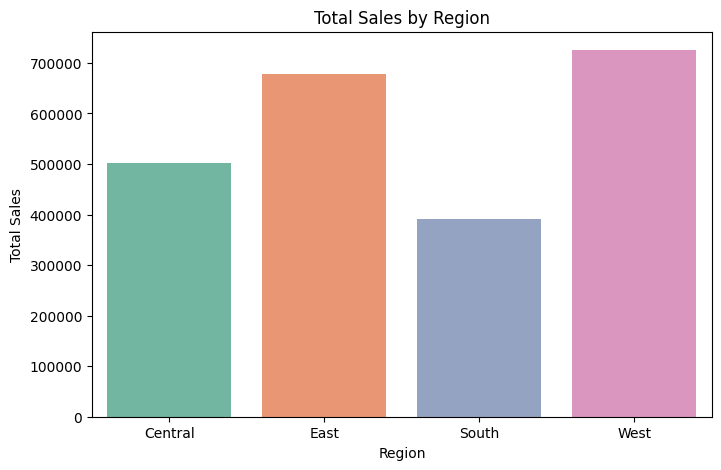

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales",
    hue="Region",
    palette="Set2",
    legend=False
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

In [124]:
region_category = df.pivot_table(
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="sum"
)

print(region_category)

Category    Furniture  Office Supplies  Technology
Region                                            
Central   163797.1638       167026.415  170416.312
East      208291.2040       205516.055  264973.981
South     117298.6840       125651.313  148771.908
West      252612.7435       220853.249  251991.832


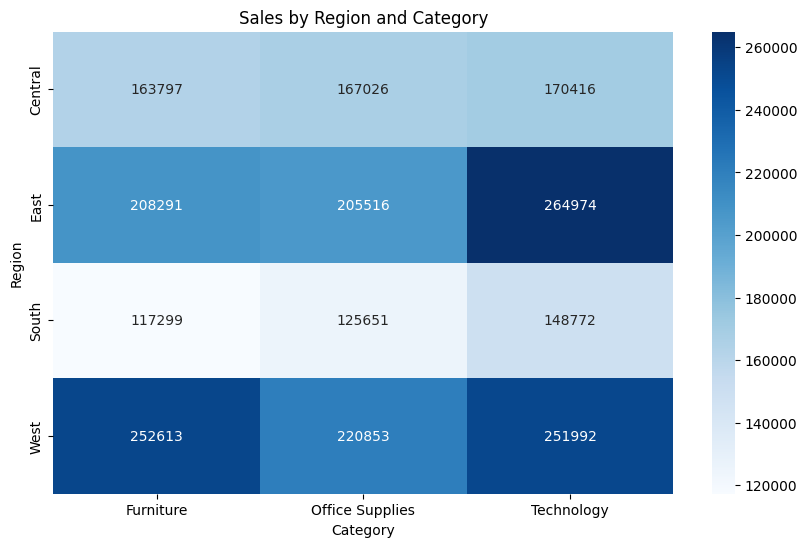

In [125]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    region_category,
    cmap="Blues",
    annot=True,
    fmt=".0f"
)

plt.title("Sales by Region and Category")
plt.xlabel("Category")
plt.ylabel("Region")

plt.show()

In [126]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [127]:
monthly_profit = (
    df.groupby(df["Order Date"].dt.month)["Profit"]
    .sum()
    .reset_index()
)

monthly_profit.columns = ["Month", "Profit"]

print(monthly_profit)

    Month      Profit
0       1   9134.4461
1       2  10294.6107
2       3  28594.6872
3       4  11587.4363
4       5  22411.3078
5       6  21285.7954
6       7  13832.6648
7       8  21776.9384
8       9  36857.4753
9      10  31784.0413
10     11  35468.4265
11     12  43369.1919


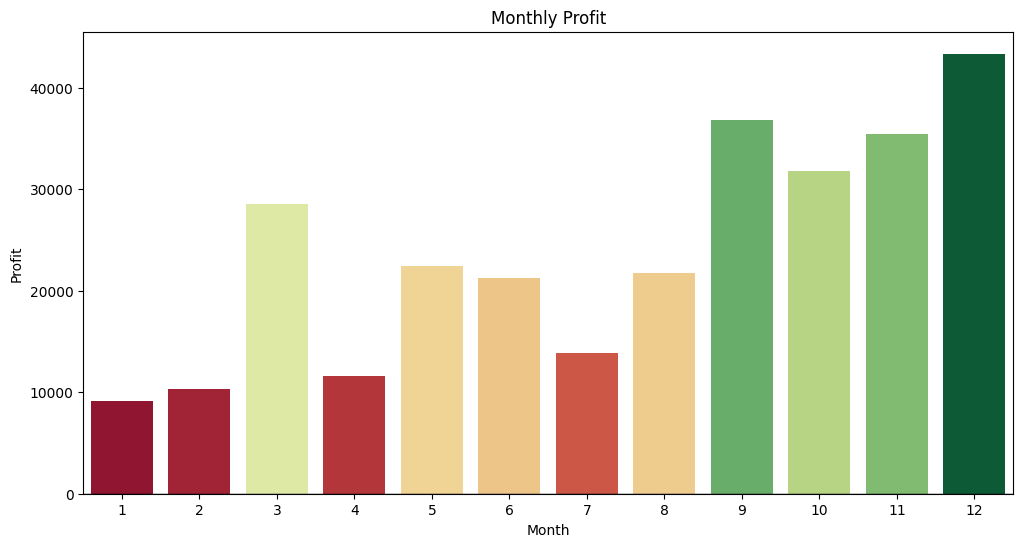

In [128]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=monthly_profit,
    x="Month",
    y="Profit",
    hue="Profit",
    palette="RdYlGn",
    legend=False
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Monthly Profit")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.show()

In [129]:
def contrast_ratio(rgb1, rgb2):

    def relative_luminance(rgb):
        # Convert 0-255 RGB to 0-1
        rgb = [value / 255 for value in rgb]

        # Convert to linear RGB
        rgb = [
            ((value + 0.055) / 1.055) ** 2.4
            if value > 0.04045
            else value / 12.92
            for value in rgb
        ]

        # Calculate luminance
        return (
            0.2126 * rgb[0] +
            0.7152 * rgb[1] +
            0.0722 * rgb[2]
        )

    L1 = relative_luminance(rgb1)
    L2 = relative_luminance(rgb2)

    lighter = max(L1, L2)
    darker = min(L1, L2)

    return (lighter + 0.05) / (darker + 0.05)

In [130]:
black = (0, 0, 0)
white = (255, 255, 255)

ratio = contrast_ratio(black, white)

print("Contrast ratio:", ratio)

Contrast ratio: 21.0


In [131]:
palette = sns.color_palette("Set2", 4)

for i, color in enumerate(palette):
    rgb = tuple(int(value * 255) for value in color)

    ratio = contrast_ratio(rgb, (255, 255, 255))

    print(
        f"Color {i+1}: RGB {rgb} | "
        f"Contrast: {ratio:.2f}:1 | "
        f"{'PASS' if ratio >= 4.5 else 'FAIL'}"
    )

Color 1: RGB (102, 194, 165) | Contrast: 2.14:1 | FAIL
Color 2: RGB (252, 141, 98) | Contrast: 2.30:1 | FAIL
Color 3: RGB (141, 160, 203) | Contrast: 2.62:1 | FAIL
Color 4: RGB (231, 138, 195) | Contrast: 2.38:1 | FAIL


In [132]:
profit_subcategory = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .reset_index()
)

print(profit_subcategory)

   Sub-Category      Profit
0   Accessories  41936.6357
1    Appliances  18138.0054
2           Art   6527.7870
3       Binders  30221.7633
4     Bookcases  -3472.5560
5        Chairs  26590.1663
6       Copiers  55617.8249
7     Envelopes   6964.1767
8     Fasteners    949.5182
9   Furnishings  13059.1436
10       Labels   5546.2540
11     Machines   3384.7569
12        Paper  34053.5693
13       Phones  44515.7306
14      Storage  21278.8264
15     Supplies  -1189.0995
16       Tables -17725.4811


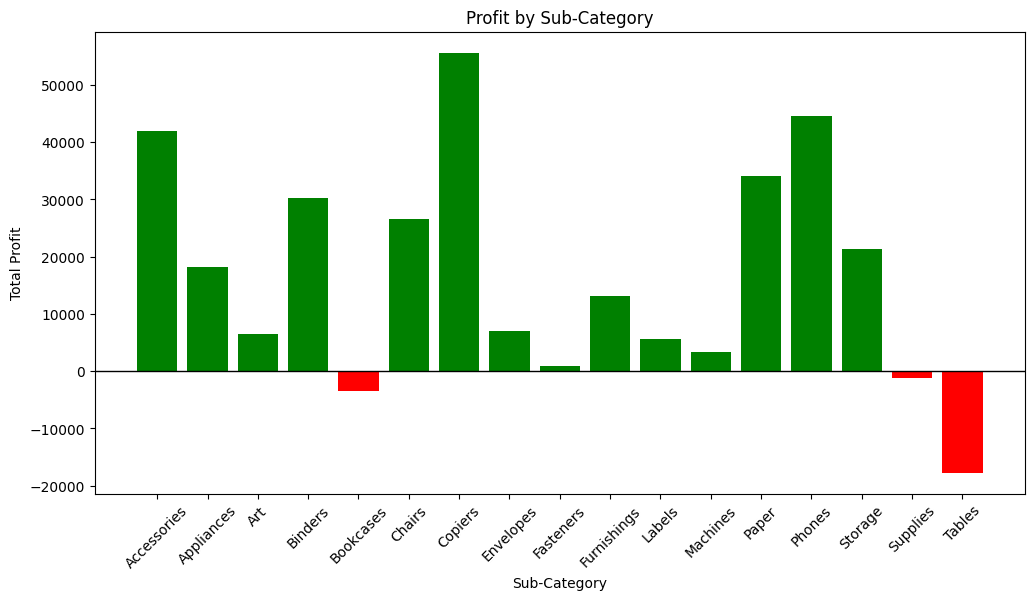

In [133]:
plt.figure(figsize=(12, 6))

colors = [
    "green" if profit >= 0 else "red"
    for profit in profit_subcategory["Profit"]
]

plt.bar(
    profit_subcategory["Sub-Category"],
    profit_subcategory["Profit"],
    color=colors
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)

plt.show()

In [134]:
region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .reset_index()
)

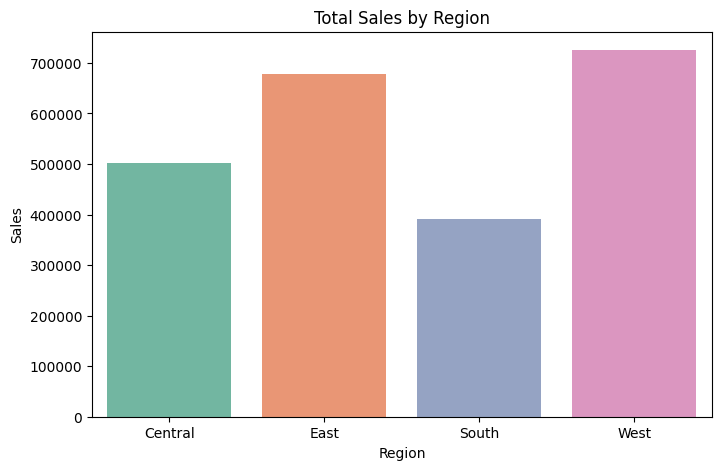

In [135]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales",
    hue="Region",
    palette="Set2",
    legend=False
)

plt.title("Total Sales by Region")
plt.show()

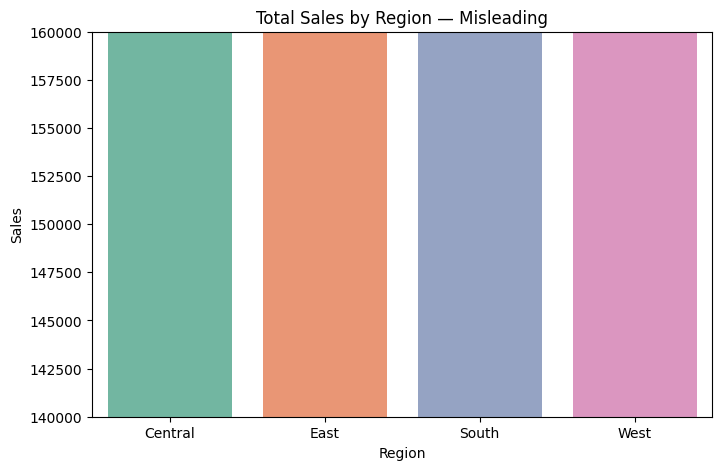

In [136]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales",
    hue="Region",
    palette="Set2",
    legend=False
)

plt.ylim(140000, 160000)

plt.title("Total Sales by Region — Misleading")
plt.show()

In [137]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = (
    df.groupby(df["Order Date"].dt.month)["Sales"]
    .sum()
)

monthly_profit = (
    df.groupby(df["Order Date"].dt.month)["Profit"]
    .sum()
)

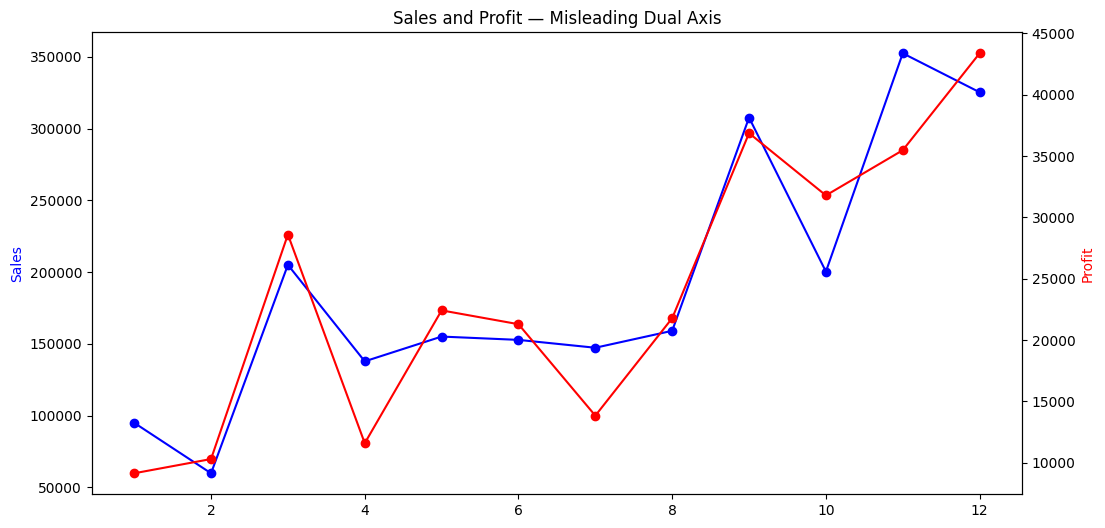

In [138]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="blue",
    marker="o"
)

ax1.set_ylabel("Sales", color="blue")

ax2 = ax1.twinx()

ax2.plot(
    monthly_profit.index,
    monthly_profit.values,
    color="red",
    marker="o"
)

ax2.set_ylabel("Profit", color="red")

plt.title("Sales and Profit — Misleading Dual Axis")

plt.show()

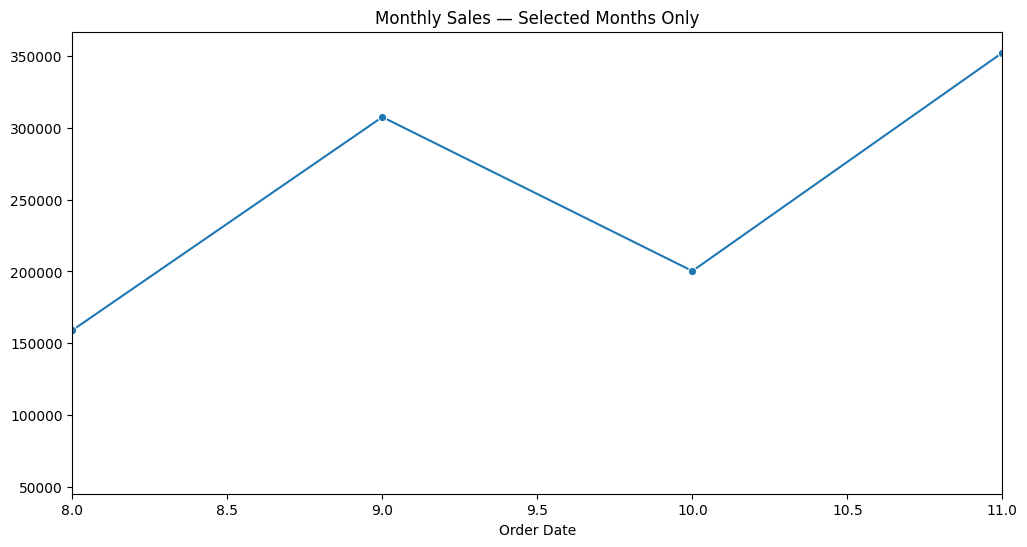

In [139]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.xlim(8, 11)

plt.title("Monthly Sales — Selected Months Only")

plt.show()

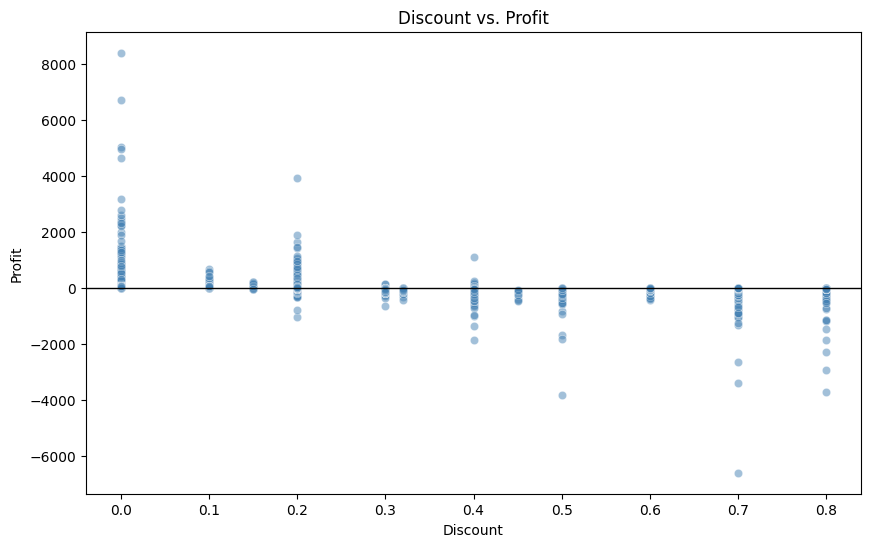

In [140]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    color="steelblue",
    alpha=0.5
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Discount vs. Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()